In [ ]:
MODULE 1 - DATA COLLECTION AND PREPROCESSING

In [1]:

# Credit Risk Analysis System

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving loan_approval_dataset.csv to loan_approval_dataset.csv


In [3]:

df = pd.read_csv('loan_approval_dataset.csv')

print("Dataset loaded successfully!")

df.head()


Dataset loaded successfully!


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (4269, 13)

Column Names:
['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  42

In [5]:

print("Missing Values in Each Column:")

print(df.isnull().sum())


Missing Values in Each Column:
loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64


In [6]:

print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [7]:

# Remove duplicate rows

df = df.drop_duplicates()

print("Duplicate rows removed successfully!")

print("New Dataset Shape:", df.shape)


Duplicate rows removed successfully!
New Dataset Shape: (4269, 13)


In [8]:

# Remove extra spaces from column names

df.columns = df.columns.str.strip()

print("Clean Column Names:")
print(df.columns.tolist())


Clean Column Names:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [9]:

df.head()


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [10]:

# Check missing values

print(df.isnull().sum())

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values handled!")
print(df.isnull().sum())


loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Missing values handled!
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [11]:

# Identify categorical columns

categorical_columns = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")

for col in categorical_columns:
    print("\nColumn:", col)
    print("Unique Values:", df[col].unique())


Categorical Columns:

Column: education
Unique Values: [' Graduate' ' Not Graduate']

Column: self_employed
Unique Values: [' No' ' Yes']

Column: loan_status
Unique Values: [' Approved' ' Rejected']


In [12]:

# Categorical Encoding

from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

label_encoders = {}

for col in df_encoded.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le

print("Categorical Encoding Completed!")

print(df_encoded.head())


Categorical Encoding Completed!
   loan_id  no_of_dependents  education  self_employed  income_annum  \
0        1                 2          0              0       9600000   
1        2                 0          1              1       4100000   
2        3                 3          0              0       9100000   
3        4                 3          0              0       8200000   
4        5                 5          1              1       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value  loan_status  
0                 17600000             227000

In [13]:

from sklearn.preprocessing import MinMaxScaler

# Create a copy
df_normalized = df_encoded.copy()

# Apply normalization
scaler = MinMaxScaler()

df_normalized[df_normalized.columns] = scaler.fit_transform(
    df_normalized[df_normalized.columns]
)

print("Normalization Completed!")

print(df_normalized.head())


Normalization Completed!
    loan_id  no_of_dependents  education  self_employed  income_annum  \
0  0.000000               0.4        0.0            0.0      0.969072   
1  0.000234               0.0        1.0            1.0      0.402062   
2  0.000469               0.6        0.0            0.0      0.917526   
3  0.000703               0.6        0.0            0.0      0.824742   
4  0.000937               1.0        1.0            1.0      0.989691   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     0.755102   0.555556     0.796667                  0.085616   
1     0.303571   0.333333     0.195000                  0.095890   
2     0.750000   1.000000     0.343333                  0.246575   
3     0.775510   0.333333     0.278333                  0.626712   
4     0.609694   1.000000     0.136667                  0.428082   

   commercial_assets_value  luxury_assets_value  bank_asset_value  loan_status  
0                 0.907216             0.57583

In [14]:

print("Minimum Values:")
print(df_normalized.min())

print("\nMaximum Values:")
print(df_normalized.max())


Minimum Values:
loan_id                     0.0
no_of_dependents            0.0
education                   0.0
self_employed               0.0
income_annum                0.0
loan_amount                 0.0
loan_term                   0.0
cibil_score                 0.0
residential_assets_value    0.0
commercial_assets_value     0.0
luxury_assets_value         0.0
bank_asset_value            0.0
loan_status                 0.0
dtype: float64

Maximum Values:
loan_id                     1.0
no_of_dependents            1.0
education                   1.0
self_employed               1.0
income_annum                1.0
loan_amount                 1.0
loan_term                   1.0
cibil_score                 1.0
residential_assets_value    1.0
commercial_assets_value     1.0
luxury_assets_value         1.0
bank_asset_value            1.0
loan_status                 1.0
dtype: float64


In [15]:

# Final Dataset Verification

print("Dataset Shape:", df_normalized.shape)

print("\nMissing Values:")
print(df_normalized.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_normalized.duplicated().sum())

print("\nDataset Preview:")
display(df_normalized.head())

print("\nModule 1 Verification Completed!")


Dataset Shape: (4269, 13)

Missing Values:
0

Duplicate Rows:
0

Dataset Preview:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,0.000000,0.4,0.0,0.0,0.969072,0.755102,0.555556,0.796667,0.085616,0.907216,0.575835,0.544218,0.0
1,0.000234,0.0,1.0,1.0,0.402062,0.303571,0.333333,0.195000,0.095890,0.113402,0.218509,0.224490,1.0
2,0.000469,0.6,0.0,0.0,0.917526,0.750000,1.000000,0.343333,0.246575,0.231959,0.848329,0.870748,1.0
3,0.000703,0.6,0.0,0.0,0.824742,0.775510,0.333333,0.278333,0.626712,0.170103,0.591260,0.537415,1.0
4,0.000937,1.0,1.0,1.0,0.989691,0.609694,1.000000,0.136667,0.428082,0.422680,0.748072,0.340136,1.0



Module 1 Verification Completed!


In [16]:

df_normalized.to_csv(
    'cleaned_credit_risk_dataset.csv',
    index=False
)

print("Cleaned Dataset Saved Successfully!")


Cleaned Dataset Saved Successfully!


In [17]:

from sklearn.preprocessing import MinMaxScaler, LabelEncoder

# Start from cleaned original dataset
df_final = df.copy()

# Identify target and ID columns
target = 'loan_status'
id_cols = ['loan_id'] if 'loan_id' in df_final.columns else []

# Encode categorical input columns
cat_cols = df_final.select_dtypes(include='object').columns.tolist()
cat_cols = [c for c in cat_cols if c not in id_cols + [target]]

df_final = pd.get_dummies(
    df_final,
    columns=cat_cols,
    dtype=int
)

# Encode target separately
if target in df_final.columns and df_final[target].dtype == 'object':
    le = LabelEncoder()
    df_final[target] = le.fit_transform(df_final[target])

# Normalize numerical input features only
numeric_cols = df_final.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in id_cols + [target]]

scaler = MinMaxScaler()
df_final[numeric_cols] = scaler.fit_transform(df_final[numeric_cols])

print("Final preprocessing completed!")
print(df_final.head())
print("Dataset Shape:", df_final.shape)


Final preprocessing completed!
   loan_id  no_of_dependents  income_annum  loan_amount  loan_term  \
0        1               0.4      0.969072     0.755102   0.555556   
1        2               0.0      0.402062     0.303571   0.333333   
2        3               0.6      0.917526     0.750000   1.000000   
3        4               0.6      0.824742     0.775510   0.333333   
4        5               1.0      0.989691     0.609694   1.000000   

   cibil_score  residential_assets_value  commercial_assets_value  \
0     0.796667                  0.085616                 0.907216   
1     0.195000                  0.095890                 0.113402   
2     0.343333                  0.246575                 0.231959   
3     0.278333                  0.626712                 0.170103   
4     0.136667                  0.428082                 0.422680   

   luxury_assets_value  bank_asset_value  loan_status  education_ Graduate  \
0             0.575835          0.544218            0  

In [18]:

df_final.to_csv(
    'final_credit_risk_dataset.csv',
    index=False
)

print("Final Dataset Saved Successfully!")


Final Dataset Saved Successfully!


In [19]:

print("========== MODULE 1 FINAL REPORT ==========")

print("Dataset Shape:", df_final.shape)

print("\nMissing Values:",
      df_final.isnull().sum().sum())

print("\nDuplicate Rows:",
      df_final.duplicated().sum())

print("\nColumn Names:")
print(df_final.columns.tolist())

print("\nTarget Distribution:")
print(df_final['loan_status'].value_counts())

print("\nFinal Dataset:")
display(df_final.head())

print("\nMODULE 1 QUALITY CHECK COMPLETED!")


========== MODULE 1 FINAL REPORT ==========
Dataset Shape: (4269, 15)

Missing Values: 0

Duplicate Rows: 0

Column Names:
['loan_id', 'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status', 'education_ Graduate', 'education_ Not Graduate', 'self_employed_ No', 'self_employed_ Yes']

Target Distribution:
loan_status
0    2656
1    1613
Name: count, dtype: int64

Final Dataset:


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,education_ Graduate,education_ Not Graduate,self_employed_ No,self_employed_ Yes
0,1,0.4,0.969072,0.755102,0.555556,0.796667,0.085616,0.907216,0.575835,0.544218,0,1.0,0.0,1.0,0.0
1,2,0.0,0.402062,0.303571,0.333333,0.195000,0.095890,0.113402,0.218509,0.224490,1,0.0,1.0,0.0,1.0
2,3,0.6,0.917526,0.750000,1.000000,0.343333,0.246575,0.231959,0.848329,0.870748,1,1.0,0.0,1.0,0.0
3,4,0.6,0.824742,0.775510,0.333333,0.278333,0.626712,0.170103,0.591260,0.537415,1,1.0,0.0,1.0,0.0
4,5,1.0,0.989691,0.609694,1.000000,0.136667,0.428082,0.422680,0.748072,0.340136,1,0.0,1.0,0.0,1.0



MODULE 1 QUALITY CHECK COMPLETED!


In [ ]:
MODULE 2 - EXPLORATORY DATA ANALYSIS (EDA)

In [20]:

# Module 2 - Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

print("Module 2 Started Successfully!")

print("\nDataset Information:")
df.head()


Module 2 Started Successfully!

Dataset Information:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [21]:

# Step 2.2 - Dataset Overview

print("Number of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Data Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())

print("\nCategorical Data Summary:")
display(df.describe(include='object'))


Number of Rows and Columns:
(4269, 13)

Column Names:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Dataset Data Types:
loan_id                      int64
no_of_dependents             int64
education                   object
self_employed               object
income_annum                 int64
loan_amount                  int64
loan_term                    int64
cibil_score                  int64
residential_assets_value     int64
commercial_assets_value      int64
luxury_assets_value          int64
bank_asset_value             int64
loan_status                 object
dtype: object

Statistical Summary:


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07



Categorical Data Summary:


,education,self_employed,loan_status
count,4269,4269,4269
unique,2,2,2
top,Graduate,Yes,Approved
freq,2144,2150,2656


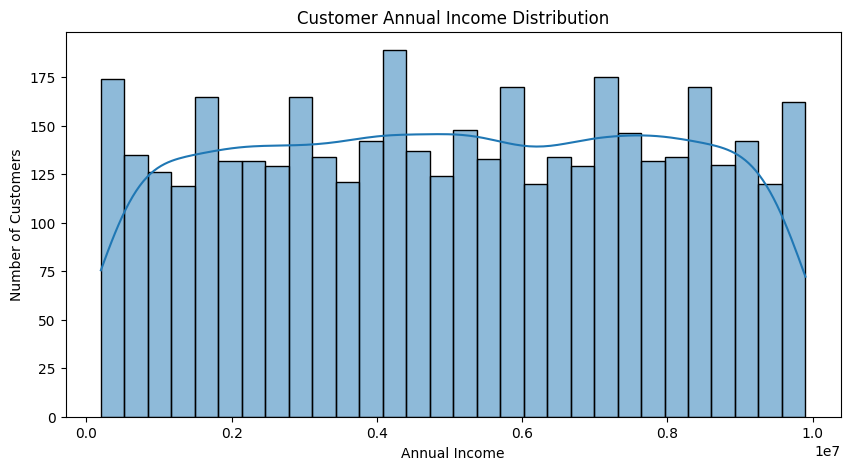

In [22]:

# Step 2.3 - Customer Income Analysis

plt.figure(figsize=(10,5))

sns.histplot(
    df['income_annum'],
    bins=30,
    kde=True
)

plt.title('Customer Annual Income Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Number of Customers')

plt.show()


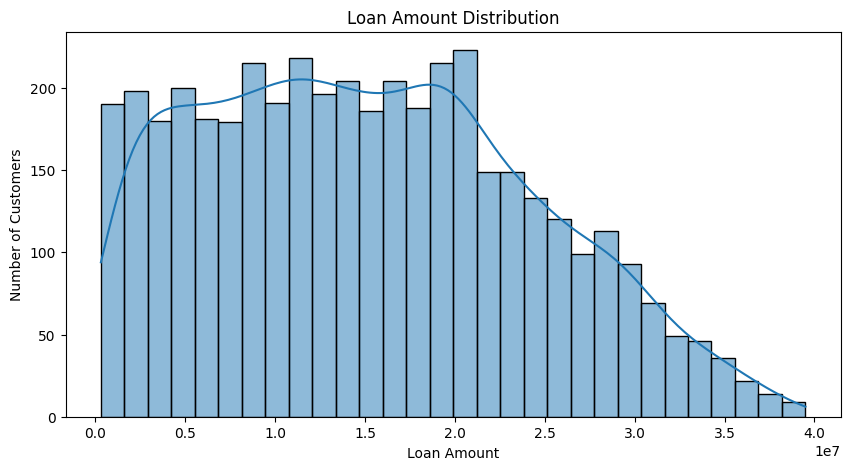

In [23]:

# Step 2.4 - Loan Amount Analysis

plt.figure(figsize=(10,5))

sns.histplot(
    df['loan_amount'],
    bins=30,
    kde=True
)

plt.title('Loan Amount Distribution')
plt.xlabel('Loan Amount')
plt.ylabel('Number of Customers')

plt.show()


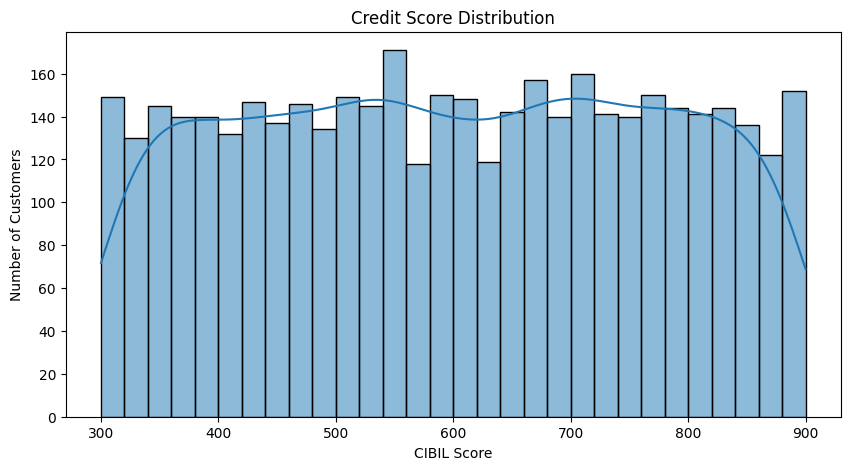

In [24]:

# Step 2.5 - Credit Score Analysis

plt.figure(figsize=(10,5))

sns.histplot(
    df['cibil_score'],
    bins=30,
    kde=True
)

plt.title('Credit Score Distribution')
plt.xlabel('CIBIL Score')
plt.ylabel('Number of Customers')

plt.show()


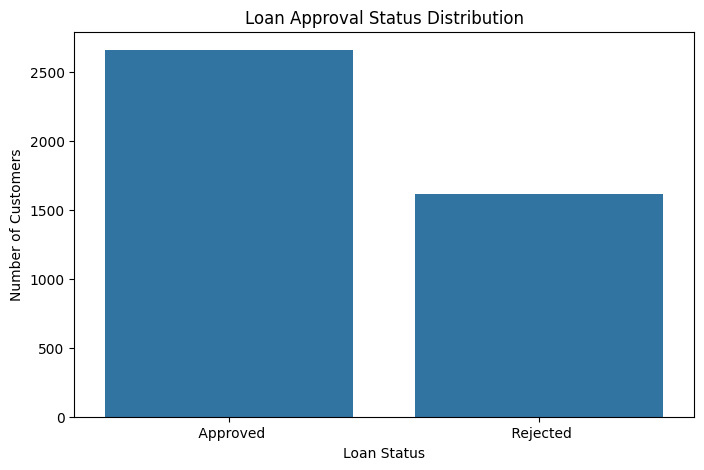


Loan Status Count:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [25]:

# Step 2.6 - Loan Status Analysis

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='loan_status'
)

plt.title('Loan Approval Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Customers')

plt.show()

print("\nLoan Status Count:")
print(df['loan_status'].value_counts())


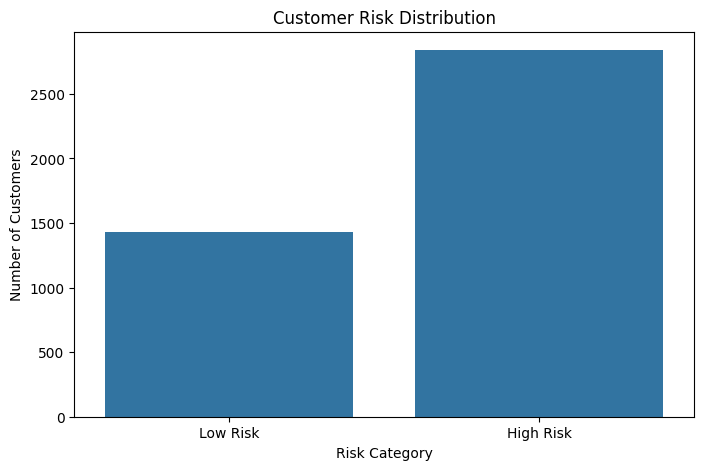


Risk Category Count:
risk_category
High Risk    2839
Low Risk     1430
Name: count, dtype: int64


In [26]:

# Step 2.7 - Loan Risk Distribution

df['risk_category'] = df['cibil_score'].apply(
    lambda score: 'Low Risk' if score >= 700 else 'High Risk'
)

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='risk_category'
)

plt.title('Customer Risk Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

plt.show()

print("\nRisk Category Count:")
print(df['risk_category'].value_counts())


Risk Category vs Loan Status:


loan_status,Approved,Rejected
risk_category,,
High Risk,1233,1606
Low Risk,1423,7


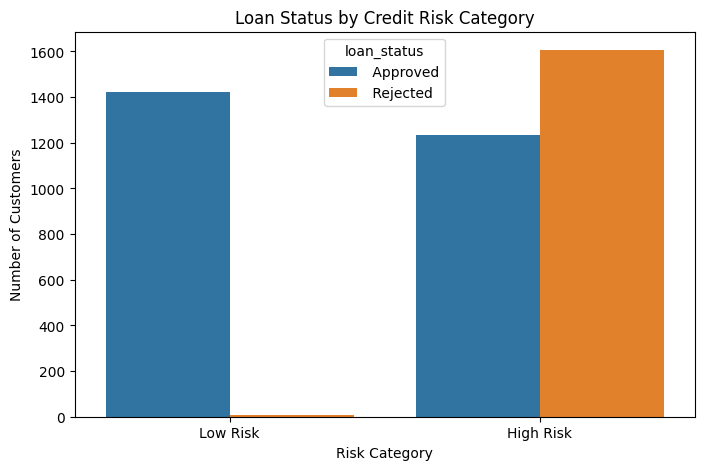

In [27]:
# Risk Category vs Loan Status Analysis

print("Risk Category vs Loan Status:")
display(pd.crosstab(df['risk_category'], df['loan_status']))

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='risk_category', hue='loan_status')

plt.title('Loan Status by Credit Risk Category')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')
plt.show()

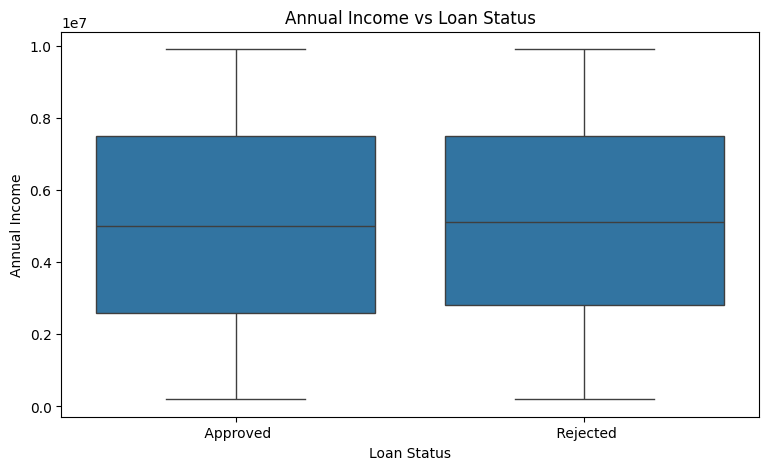

Income Analysis Completed!


In [28]:
# Income vs Loan Status Analysis

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='income_annum'
)

plt.title('Annual Income vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Annual Income')
plt.show()

print("Income Analysis Completed!")

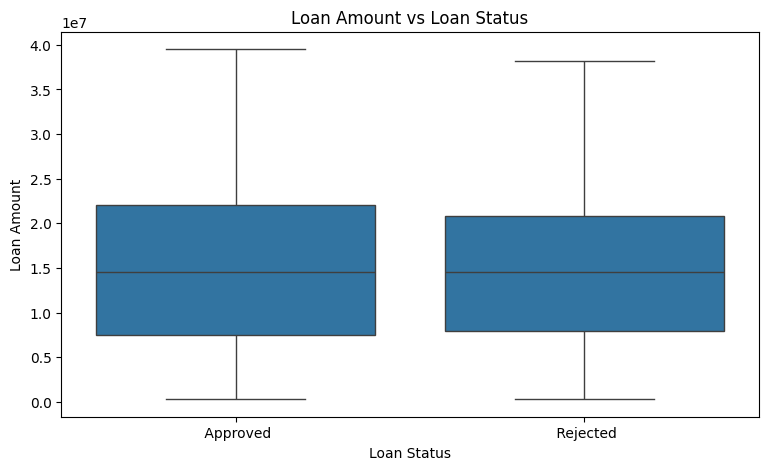

Loan Amount Analysis Completed!


In [29]:
# Loan Amount vs Loan Status Analysis

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='loan_status',
    y='loan_amount'
)

plt.title('Loan Amount vs Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Loan Amount')
plt.show()

print("Loan Amount Analysis Completed!")

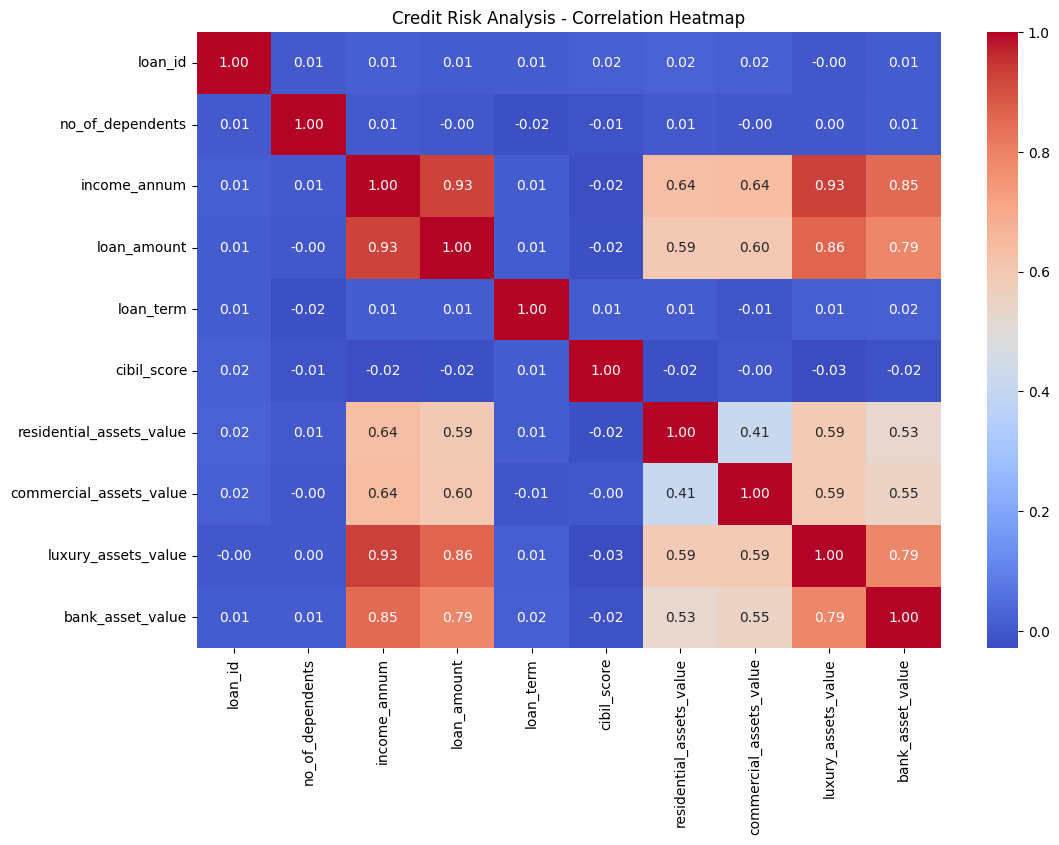

Correlation Heatmap Created Successfully!


In [30]:
# Correlation Heatmap

numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12,8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Credit Risk Analysis - Correlation Heatmap')
plt.show()

print("Correlation Heatmap Created Successfully!")

In [31]:
# MODULE 2 - EDA FINAL SUMMARY

print("========== MODULE 2 FINAL REPORT ==========")

print("\n1. Total Customers:")
print(len(df))

print("\n2. Loan Status Distribution:")
print(df['loan_status'].value_counts())

print("\n3. Risk Category Distribution:")
print(df['risk_category'].value_counts())

print("\n4. Average Annual Income:")
print(df['income_annum'].mean())

print("\n5. Average Loan Amount:")
print(df['loan_amount'].mean())

print("\n6. Average CIBIL Score:")
print(df['cibil_score'].mean())

print("\n7. Missing Values:")
print(df.isnull().sum().sum())

print("\nMODULE 2 EDA COMPLETED!")

========== MODULE 2 FINAL REPORT ==========

1. Total Customers:
4269

2. Loan Status Distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

3. Risk Category Distribution:
risk_category
High Risk    2839
Low Risk     1430
Name: count, dtype: int64

4. Average Annual Income:
5059123.9166081045

5. Average Loan Amount:
15133450.456781447

6. Average CIBIL Score:
599.9360505973295

7. Missing Values:
0

MODULE 2 EDA COMPLETED!


In [ ]:
MODULE 3 - CREDIT RISK PREDICTION MODEL

In [32]:
# MODULE 3 - CREDIT RISK PREDICTION MODEL

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Module 3 Started Successfully!")

Module 3 Started Successfully!


In [33]:
# Step 3.2 - Separate Input and Target

X = df_final.drop(columns=['loan_status', 'loan_id'], errors='ignore')

y = df_final['loan_status']

print("Input Data (X) Shape:", X.shape)
print("Target Data (y) Shape:", y.shape)

print("\nInput Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nInput and Target Separated Successfully!")

Input Data (X) Shape: (4269, 13)
Target Data (y) Shape: (4269,)

Input Columns:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'education_ Graduate', 'education_ Not Graduate', 'self_employed_ No', 'self_employed_ Yes']

Target Distribution:
loan_status
0    2656
1    1613
Name: count, dtype: int64

Input and Target Separated Successfully!


In [34]:
# Step 3.3 - Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining and Testing Data Split Successfully!")

Training Data Shape: (3415, 13)
Testing Data Shape: (854, 13)

Training Target Shape: (3415,)
Testing Target Shape: (854,)

Training and Testing Data Split Successfully!


In [35]:
# Step 3.4 - Logistic Regression Model

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [36]:
# Step 3.5 - Logistic Regression Prediction

y_pred_log = log_model.predict(X_test)

log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:")
print(log_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_log))

Logistic Regression Accuracy:
92.50585480093677 %

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       531
           1       0.92      0.87      0.90       323

    accuracy                           0.93       854
   macro avg       0.92      0.91      0.92       854
weighted avg       0.93      0.93      0.92       854


Confusion Matrix:
[[508  23]
 [ 41 282]]


In [37]:
# Step 3.6 - Decision Tree Model

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [38]:
# Step 3.7 - Decision Tree Prediction

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:")
print(dt_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy:
97.7751756440281 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       531
           1       0.95      0.99      0.97       323

    accuracy                           0.98       854
   macro avg       0.97      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Confusion Matrix:
[[515  16]
 [  3 320]]


In [39]:
# Step 3.8 - Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [40]:
# Step 3.9 - Random Forest Prediction

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:")
print(rf_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy:
98.12646370023418 %

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       531
           1       0.99      0.96      0.97       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Confusion Matrix:
[[528   3]
 [ 13 310]]


,Model,Accuracy (%)
0,Logistic Regression,92.505855
1,Decision Tree,97.775176
2,Random Forest,98.126464


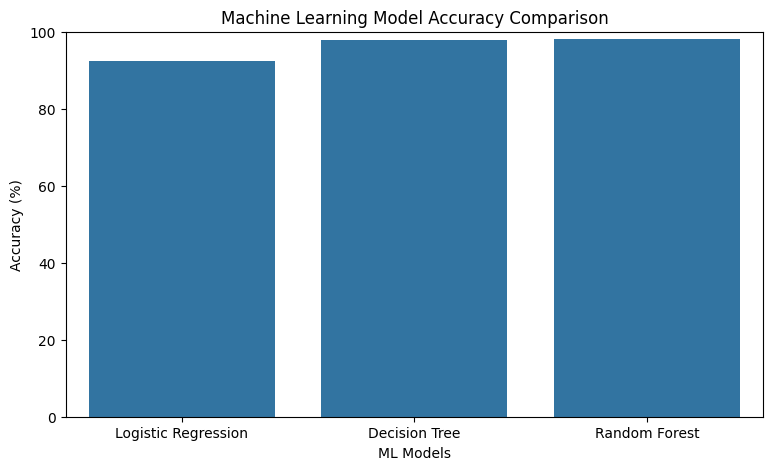

Model Comparison Completed!


In [41]:
# Step 3.10 - Model Accuracy Comparison

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy (%)': [
        log_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})

display(model_comparison)

plt.figure(figsize=(9,5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy (%)'
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.xlabel('ML Models')
plt.ylim(0, 100)
plt.show()

print("Model Comparison Completed!")

In [42]:
# Step 3.11 - Best Model Selection

models = {
    'Logistic Regression': log_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model
}

best_model_name = model_comparison.loc[
    model_comparison['Accuracy (%)'].idxmax(), 'Model'
]

best_model = models[best_model_name]

best_accuracy = model_comparison['Accuracy (%)'].max()

print("Best Model:", best_model_name)
print("Best Model Accuracy:", round(best_accuracy, 2), "%")

print("\nBest Model Selected Successfully!")

Best Model: Random Forest
Best Model Accuracy: 98.13 %

Best Model Selected Successfully!


In [43]:
# Step 3.12 - Best Model Final Evaluation

best_predictions = best_model.predict(X_test)

print("BEST MODEL:", best_model_name)

print("\nFinal Accuracy:")
print(round(accuracy_score(y_test, best_predictions) * 100, 2), "%")

print("\nFinal Classification Report:")
print(classification_report(y_test, best_predictions))

print("\nFinal Confusion Matrix:")
print(confusion_matrix(y_test, best_predictions))

print("\nMODULE 3 MODEL EVALUATION COMPLETED!")

BEST MODEL: Random Forest

Final Accuracy:
98.13 %

Final Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       531
           1       0.99      0.96      0.97       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


Final Confusion Matrix:
[[528   3]
 [ 13 310]]

MODULE 3 MODEL EVALUATION COMPLETED!


In [44]:
# Step 3.13 - Save Best Model

import joblib

joblib.dump(best_model, 'best_credit_risk_model.pkl')

print("Best Model Saved Successfully!")
print("Saved Model:", best_model_name)
print("Model File: best_credit_risk_model.pkl")

Best Model Saved Successfully!
Saved Model: Random Forest
Model File: best_credit_risk_model.pkl


In [45]:
# MODULE 3 - FINAL REPORT

print("========== MODULE 3 FINAL REPORT ==========")

print("\n1. Total Training Records:", len(X_train))
print("2. Total Testing Records:", len(X_test))

print("\n3. Logistic Regression Accuracy:")
print(round(log_accuracy * 100, 2), "%")

print("\n4. Decision Tree Accuracy:")
print(round(dt_accuracy * 100, 2), "%")

print("\n5. Random Forest Accuracy:")
print(round(rf_accuracy * 100, 2), "%")

print("\n6. Best Model:", best_model_name)
print("7. Best Model Accuracy:", round(best_accuracy, 2), "%")

print("\n8. Saved Model: best_credit_risk_model.pkl")

print("\nMODULE 3 COMPLETED SUCCESSFULLY!")

========== MODULE 3 FINAL REPORT ==========

1. Total Training Records: 3415
2. Total Testing Records: 854

3. Logistic Regression Accuracy:
92.51 %

4. Decision Tree Accuracy:
97.78 %

5. Random Forest Accuracy:
98.13 %

6. Best Model: Random Forest
7. Best Model Accuracy: 98.13 %

8. Saved Model: best_credit_risk_model.pkl

MODULE 3 COMPLETED SUCCESSFULLY!


In [ ]:
MODULE 4 - RISK SCORE DASHBOARD

In [46]:
# MODULE 4 - RISK SCORE DASHBOARD

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

print("Module 4 Started Successfully!")

Module 4 Started Successfully!


In [47]:
# Step 4.2 - Load Best Model

loaded_model = joblib.load('best_credit_risk_model.pkl')

print("Best Model Loaded Successfully!")
print("Model Name:", best_model_name)

Best Model Loaded Successfully!
Model Name: Random Forest


In [48]:
# Step 4.3 - Customer Risk Predictions

dashboard_predictions = loaded_model.predict(X_test)

dashboard_results = pd.DataFrame({
    'Actual Loan Status': y_test,
    'Predicted Loan Status': dashboard_predictions
}, index=X_test.index)

print("Customer Risk Predictions:")
display(dashboard_results.head(10))

print("\nTotal Predictions:", len(dashboard_predictions))
print("\nCustomer Predictions Generated Successfully!")

Customer Risk Predictions:


,Actual Loan Status,Predicted Loan Status
2346,0,0
1162,0,0
3061,0,0
483,1,1
2102,0,0
1002,1,1
792,1,1
2870,0,0
2475,0,0
3867,0,0



Total Predictions: 854

Customer Predictions Generated Successfully!


In [49]:
# Step 4.4 - Loan Approval Probability

approval_class = sorted(
    df['loan_status'].astype(str).str.strip().unique()
).index('Approved')

approval_index = list(loaded_model.classes_).index(approval_class)

approval_probability = (
    loaded_model.predict_proba(X_test)[:, approval_index] * 100
)

dashboard_results['Approval Probability (%)'] = approval_probability.round(2)

print("Customer Loan Approval Probability:")
display(dashboard_results.head(10))

print("\nApproval Probability Calculated Successfully!")

Customer Loan Approval Probability:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%)
2346,0,0,97.0
1162,0,0,97.0
3061,0,0,98.0
483,1,1,3.0
2102,0,0,100.0
1002,1,1,3.0
792,1,1,12.0
2870,0,0,100.0
2475,0,0,99.0
3867,0,0,100.0



Approval Probability Calculated Successfully!


In [50]:
# Step 4.5 - Customer Risk Category

dashboard_results['Risk Category'] = np.where(
    dashboard_results['Approval Probability (%)'] >= 50,
    'Lower Risk',
    'Higher Risk'
)

print("Customer Risk Category:")
display(dashboard_results.head(10))

print("\nRisk Category Distribution:")
print(dashboard_results['Risk Category'].value_counts())

print("\nRisk Categories Created Successfully!")

Customer Risk Category:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%),Risk Category
2346,0,0,97.0,Lower Risk
1162,0,0,97.0,Lower Risk
3061,0,0,98.0,Lower Risk
483,1,1,3.0,Higher Risk
2102,0,0,100.0,Lower Risk
1002,1,1,3.0,Higher Risk
792,1,1,12.0,Higher Risk
2870,0,0,100.0,Lower Risk
2475,0,0,99.0,Lower Risk
3867,0,0,100.0,Lower Risk



Risk Category Distribution:
Risk Category
Lower Risk     541
Higher Risk    313
Name: count, dtype: int64

Risk Categories Created Successfully!


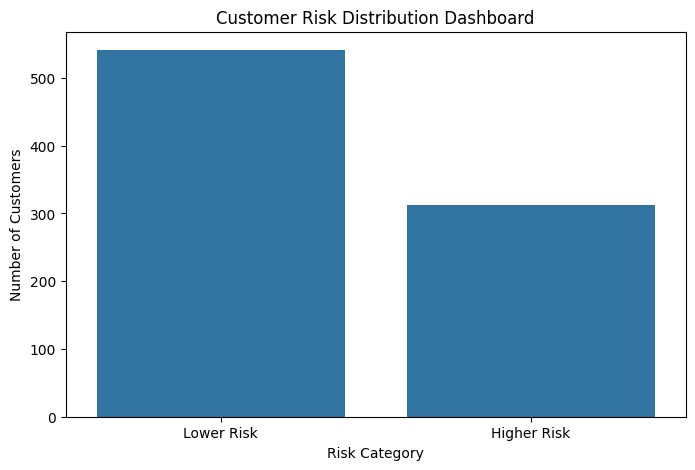

Risk Distribution Chart Created Successfully!


In [51]:
# Step 4.6 - Risk Distribution Chart

plt.figure(figsize=(8,5))

sns.countplot(
    data=dashboard_results,
    x='Risk Category'
)

plt.title('Customer Risk Distribution Dashboard')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')

plt.show()

print("Risk Distribution Chart Created Successfully!")

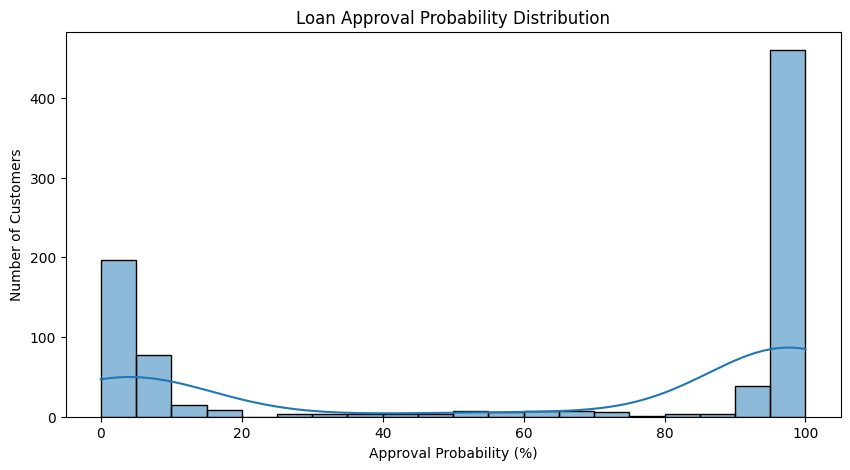

Approval Probability Chart Created Successfully!


In [52]:
# Step 4.7 - Approval Probability Chart

plt.figure(figsize=(10,5))

sns.histplot(
    data=dashboard_results,
    x='Approval Probability (%)',
    bins=20,
    kde=True
)

plt.title('Loan Approval Probability Distribution')
plt.xlabel('Approval Probability (%)')
plt.ylabel('Number of Customers')

plt.show()

print("Approval Probability Chart Created Successfully!")

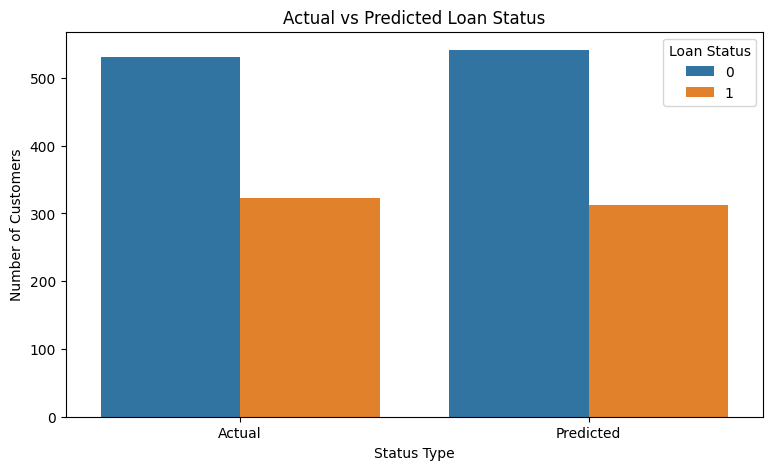

Actual vs Predicted Comparison Completed!


In [53]:
# Step 4.8 - Actual vs Predicted Loan Status

comparison_data = pd.DataFrame({
    'Status Type': ['Actual'] * len(y_test) + ['Predicted'] * len(dashboard_predictions),
    'Loan Status': list(y_test) + list(dashboard_predictions)
})

plt.figure(figsize=(9,5))

sns.countplot(
    data=comparison_data,
    x='Status Type',
    hue='Loan Status'
)

plt.title('Actual vs Predicted Loan Status')
plt.xlabel('Status Type')
plt.ylabel('Number of Customers')

plt.show()

print("Actual vs Predicted Comparison Completed!")

In [54]:
# Step 4.9 - Dashboard Summary

print("========== CREDIT RISK DASHBOARD ==========")

print("\n1. Total Customers Tested:")
print(len(dashboard_results))

print("\n2. Lower Risk Customers:")
print((dashboard_results['Risk Category'] == 'Lower Risk').sum())

print("\n3. Higher Risk Customers:")
print((dashboard_results['Risk Category'] == 'Higher Risk').sum())

print("\n4. Average Approval Probability:")
print(
    round(dashboard_results['Approval Probability (%)'].mean(), 2),
    "%"
)

print("\n5. Best ML Model:")
print(best_model_name)

print("\n6. Model Accuracy:")
print(round(best_accuracy, 2), "%")

print("\n========== DASHBOARD SUMMARY COMPLETED ==========")

========== CREDIT RISK DASHBOARD ==========

1. Total Customers Tested:
854

2. Lower Risk Customers:
541

3. Higher Risk Customers:
313

4. Average Approval Probability:
62.58 %

5. Best ML Model:
Random Forest

6. Model Accuracy:
98.13 %

========== DASHBOARD SUMMARY COMPLETED ==========


In [55]:
# Step 4.10 - Save Dashboard Results

dashboard_results.to_csv(
    'credit_risk_dashboard_results.csv',
    index=True
)

print("Dashboard Results Saved Successfully!")
print("File Name: credit_risk_dashboard_results.csv")

print("\nSaved Data Preview:")
display(dashboard_results.head())

Dashboard Results Saved Successfully!
File Name: credit_risk_dashboard_results.csv

Saved Data Preview:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%),Risk Category
2346,0,0,97.0,Lower Risk
1162,0,0,97.0,Lower Risk
3061,0,0,98.0,Lower Risk
483,1,1,3.0,Higher Risk
2102,0,0,100.0,Lower Risk


In [56]:
# Step 4.11 - Customer Analysis Dashboard

dashboard_data = dashboard_results.join(
    df.loc[X_test.index, [
        'income_annum',
        'loan_amount',
        'cibil_score'
    ]]
)

print("Customer Analysis:")
display(dashboard_data.head(10))

print("\nAverage Customer Details by Risk Category:")

display(
    dashboard_data.groupby('Risk Category')[
        ['income_annum', 'loan_amount', 'cibil_score']
    ].mean().round(2)
)

print("\nCustomer Analysis Completed Successfully!")

Customer Analysis:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%),Risk Category,income_annum,loan_amount,cibil_score
2346,0,0,97.0,Lower Risk,8000000,26200000,890
1162,0,0,97.0,Lower Risk,1900000,4200000,620
3061,0,0,98.0,Lower Risk,3300000,9600000,896
483,1,1,3.0,Higher Risk,2500000,8800000,538
2102,0,0,100.0,Lower Risk,7900000,29300000,771
1002,1,1,3.0,Higher Risk,9600000,20700000,442
792,1,1,12.0,Higher Risk,6300000,13400000,504
2870,0,0,100.0,Lower Risk,4000000,8600000,847
2475,0,0,99.0,Lower Risk,6400000,25000000,667
3867,0,0,100.0,Lower Risk,2900000,11100000,683



Average Customer Details by Risk Category:


,income_annum,loan_amount,cibil_score
Risk Category,,,
Higher Risk,5429712.46,16053674.12,427.98
Lower Risk,4962846.58,15118669.13,710.28



Customer Analysis Completed Successfully!


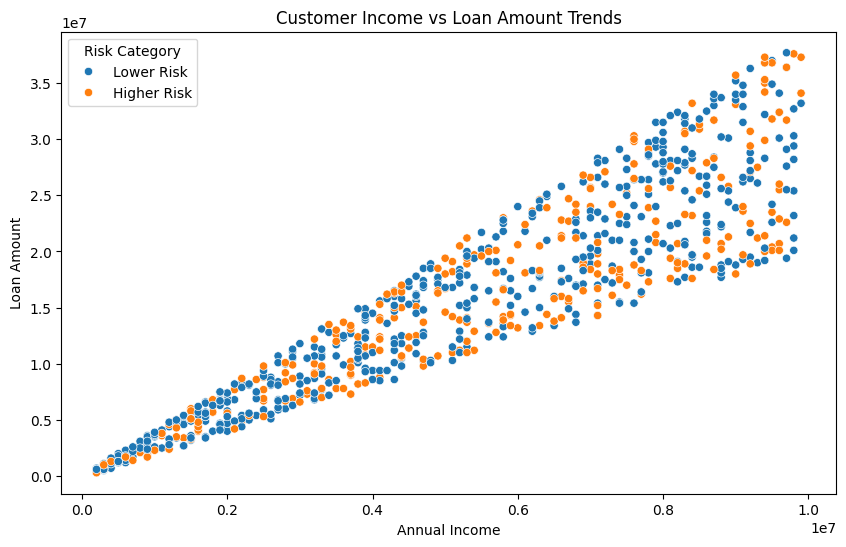

Loan Trends Analysis Completed Successfully!


In [57]:
# Step 4.12 - Loan Trends Analysis

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=dashboard_data,
    x='income_annum',
    y='loan_amount',
    hue='Risk Category'
)

plt.title('Customer Income vs Loan Amount Trends')
plt.xlabel('Annual Income')
plt.ylabel('Loan Amount')

plt.show()

print("Loan Trends Analysis Completed Successfully!")

In [58]:
# MODULE 4 - FINAL REPORT

print("========== MODULE 4 FINAL REPORT ==========")

print("\n1. Total Customers Analysed:")
print(len(dashboard_results))

print("\n2. Risk Category Distribution:")
print(dashboard_results['Risk Category'].value_counts())

print("\n3. Average Approval Probability:")
print(round(dashboard_results['Approval Probability (%)'].mean(), 2), "%")

print("\n4. Best Machine Learning Model:")
print(best_model_name)

print("\n5. Model Accuracy:")
print(round(best_accuracy, 2), "%")

print("\n6. Dashboard Results File:")
print("credit_risk_dashboard_results.csv")

print("\nMODULE 4 ANALYSIS COMPLETED!")

========== MODULE 4 FINAL REPORT ==========

1. Total Customers Analysed:
854

2. Risk Category Distribution:
Risk Category
Lower Risk     541
Higher Risk    313
Name: count, dtype: int64

3. Average Approval Probability:
62.58 %

4. Best Machine Learning Model:
Random Forest

5. Model Accuracy:
98.13 %

6. Dashboard Results File:
credit_risk_dashboard_results.csv

MODULE 4 ANALYSIS COMPLETED!


In [ ]:
MODULE 5 - FINAL RECOMMENDATION SYSTEM

In [59]:
# MODULE 5 - FINAL RECOMMENDATION SYSTEM

def loan_recommendation(probability):

    if probability >= 70:
        return 'Approve Loan'

    elif probability >= 40:
        return 'Review Manually'

    else:
        return 'Reject Application'


dashboard_results['Final Recommendation'] = (
    dashboard_results['Approval Probability (%)']
    .apply(loan_recommendation)
)

print("Loan Recommendation Results:")

display(dashboard_results.head(15))

print("\nRecommendation Distribution:")

print(
    dashboard_results['Final Recommendation'].value_counts()
)

print("\nRecommendation System Created Successfully!")

Loan Recommendation Results:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%),Risk Category,Final Recommendation
2346,0,0,97.0,Lower Risk,Approve Loan
1162,0,0,97.0,Lower Risk,Approve Loan
3061,0,0,98.0,Lower Risk,Approve Loan
483,1,1,3.0,Higher Risk,Reject Application
2102,0,0,100.0,Lower Risk,Approve Loan
1002,1,1,3.0,Higher Risk,Reject Application
792,1,1,12.0,Higher Risk,Reject Application
2870,0,0,100.0,Lower Risk,Approve Loan
2475,0,0,99.0,Lower Risk,Approve Loan
3867,0,0,100.0,Lower Risk,Approve Loan



Recommendation Distribution:
Final Recommendation
Approve Loan          514
Reject Application    306
Review Manually        34
Name: count, dtype: int64

Recommendation System Created Successfully!


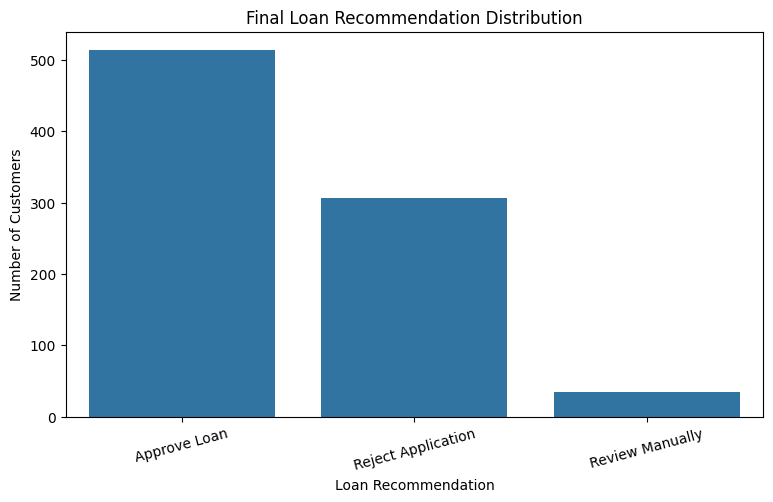

Recommendation Chart Created Successfully!


In [60]:
# Step 5.2 - Recommendation Distribution Chart

plt.figure(figsize=(9,5))

sns.countplot(
    data=dashboard_results,
    x='Final Recommendation'
)

plt.title('Final Loan Recommendation Distribution')
plt.xlabel('Loan Recommendation')
plt.ylabel('Number of Customers')

plt.xticks(rotation=15)

plt.show()

print("Recommendation Chart Created Successfully!")

In [61]:
# Step 5.3 - Final Recommendation Report

print("========== FINAL LOAN RECOMMENDATION REPORT ==========")

print("\n1. Total Customers Analysed:")
print(len(dashboard_results))

print("\n2. Approve Loan:")
print(
    (dashboard_results['Final Recommendation'] == 'Approve Loan').sum()
)

print("\n3. Review Manually:")
print(
    (dashboard_results['Final Recommendation'] == 'Review Manually').sum()
)

print("\n4. Reject Application:")
print(
    (dashboard_results['Final Recommendation'] == 'Reject Application').sum()
)

print("\n5. Best ML Model:")
print(best_model_name)

print("\n6. Model Accuracy:")
print(round(best_accuracy, 2), "%")

print("\nFINAL RECOMMENDATION REPORT COMPLETED!")

========== FINAL LOAN RECOMMENDATION REPORT ==========

1. Total Customers Analysed:
854

2. Approve Loan:
514

3. Review Manually:
34

4. Reject Application:
306

5. Best ML Model:
Random Forest

6. Model Accuracy:
98.13 %

FINAL RECOMMENDATION REPORT COMPLETED!


In [62]:
# Step 5.4 - Save Final Recommendation Dataset

dashboard_results.to_csv(
    'final_credit_risk_recommendations.csv',
    index=True
)

print("Final Recommendation Dataset Saved Successfully!")

print("\nFile Name:")
print("final_credit_risk_recommendations.csv")

print("\nFinal Dataset Preview:")
display(dashboard_results.head(10))

Final Recommendation Dataset Saved Successfully!

File Name:
final_credit_risk_recommendations.csv

Final Dataset Preview:


,Actual Loan Status,Predicted Loan Status,Approval Probability (%),Risk Category,Final Recommendation
2346,0,0,97.0,Lower Risk,Approve Loan
1162,0,0,97.0,Lower Risk,Approve Loan
3061,0,0,98.0,Lower Risk,Approve Loan
483,1,1,3.0,Higher Risk,Reject Application
2102,0,0,100.0,Lower Risk,Approve Loan
1002,1,1,3.0,Higher Risk,Reject Application
792,1,1,12.0,Higher Risk,Reject Application
2870,0,0,100.0,Lower Risk,Approve Loan
2475,0,0,99.0,Lower Risk,Approve Loan
3867,0,0,100.0,Lower Risk,Approve Loan


In [65]:
from google.colab import files

files.download('best_credit_risk_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:
from google.colab import files

files.download('final_credit_risk_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
from google.colab import files

files.download('credit_risk_dashboard_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>